In [8]:
results_dir = "/projectnb/vkolagrp/ketanss/adrd_agent_custom/adrd_agent/DiscoAD_MAS/results"

points = {
    2: [],
    3: []
}

import pandas as pd
for keyword in range(2, 4):
    path = results_dir + f"/{keyword}_keywords.csv"
    df = pd.read_csv(path)
    points[keyword] = df.groupby('run_number')['hypothesis_approved'].mean()

points[2] = pd.read_csv("/projectnb/vkolagrp/ketanss/adrd_agent_custom/adrd_agent/DiscoAD_MAS/results/hypothesis_approval_tracking_20250921_141256.csv").groupby('run_number')['hypothesis_approved'].mean()
points[3] = pd.read_csv("/projectnb/vkolagrp/ketanss/adrd_agent_custom/adrd_agent/DiscoAD_MAS/results/hypothesis_approval_tracking_20250922_032811.csv").groupby('run_number')['hypothesis_approved'].mean()

/scratch/ipykernel_131771/780397920.py:216: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data, patch_artist=True, labels=labels)
/scratch/ipykernel_131771/780397920.py:353: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')


Figure saved as: /projectnb/vkolagrp/ketanss/adrd_agent_custom/DiscoADRD/DiscoAD_MAS_with_planner_refinement/figures/figure2.pdf


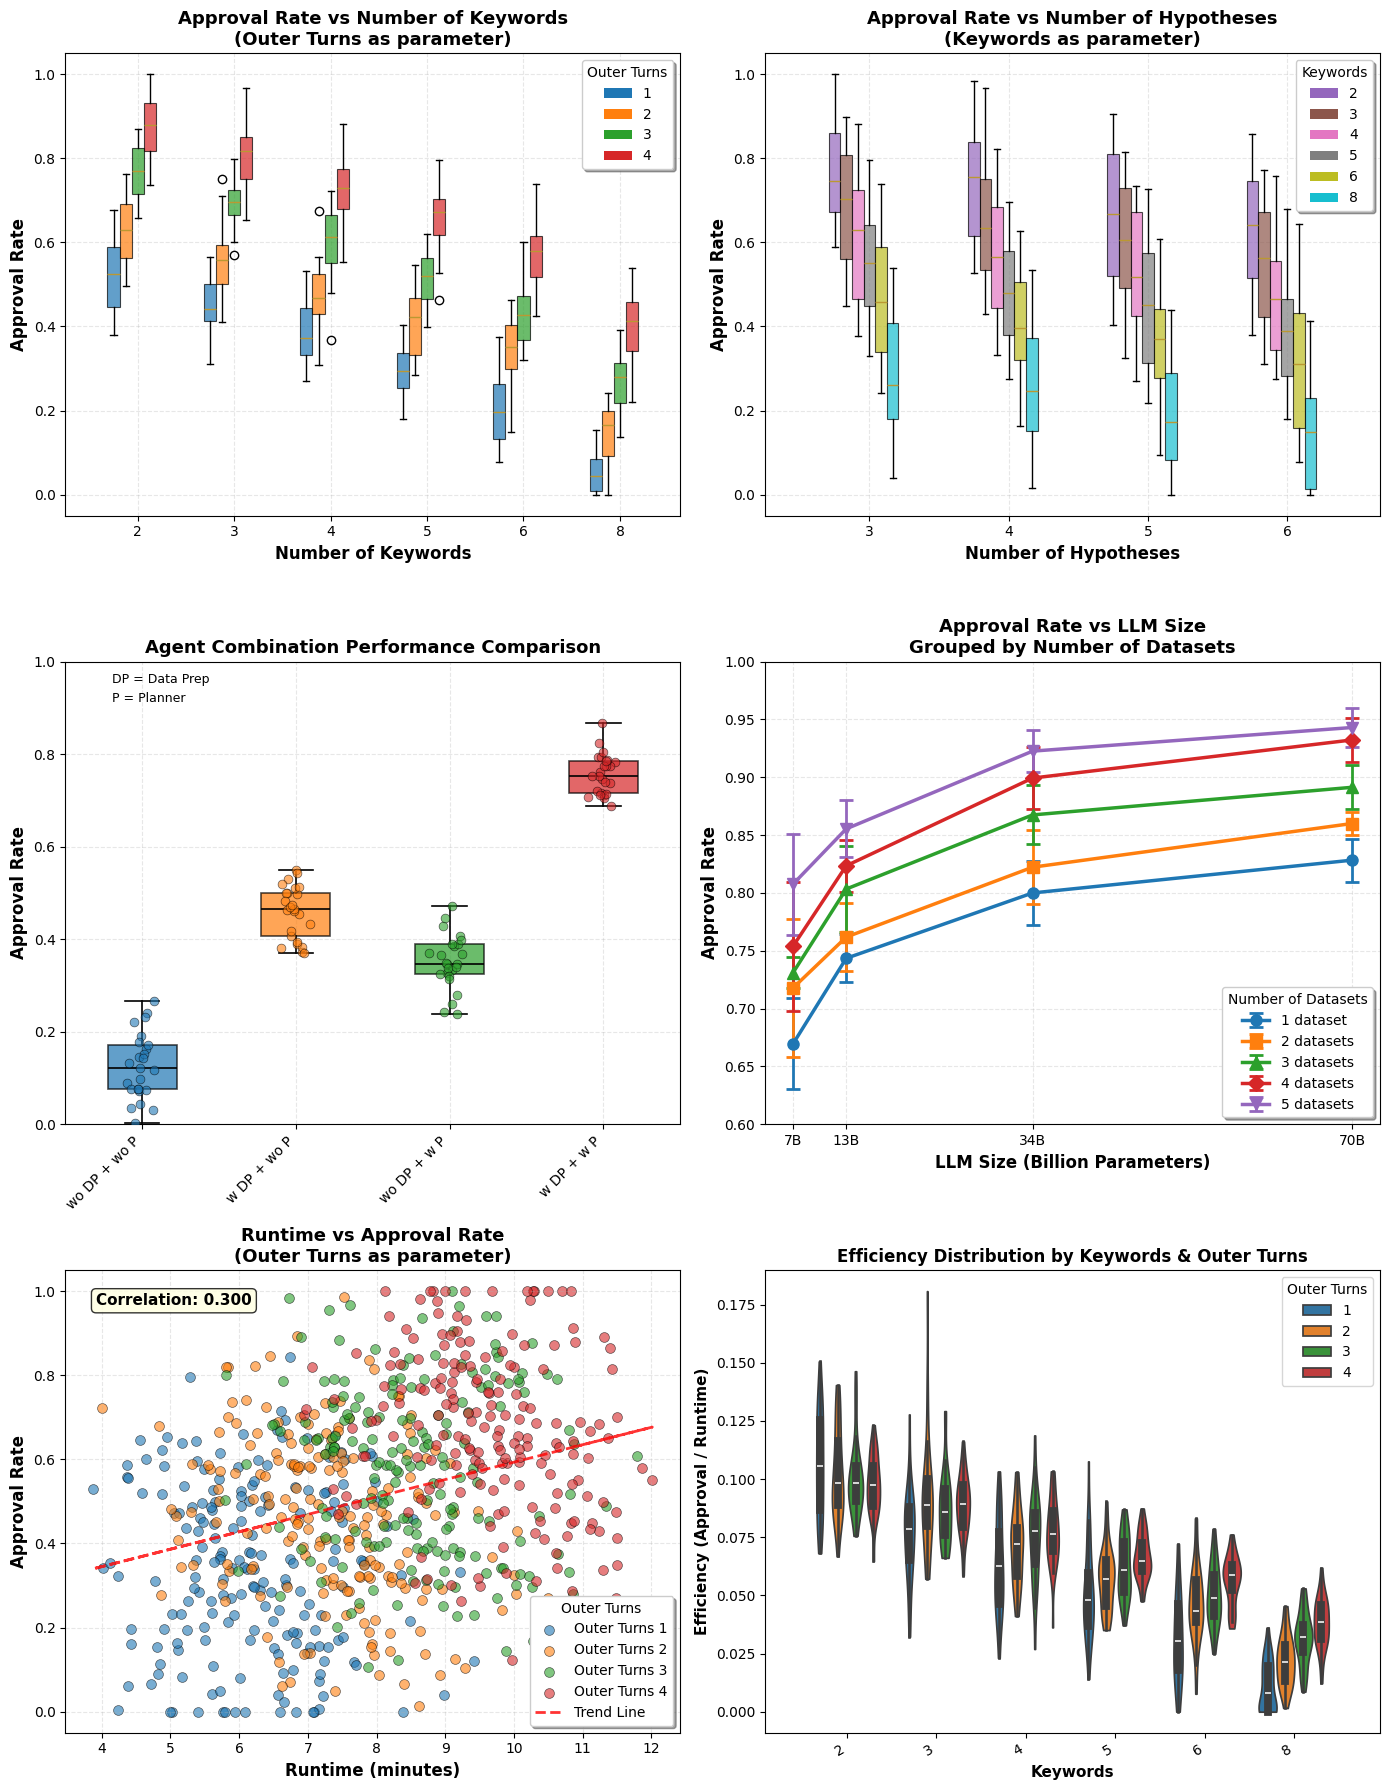

In [33]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
import seaborn as sns

# Set style for nature journal publication
plt.style.use('default')
sns.set_palette("husl")

# Nature journal color palette (accessible colors)
nature_colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

np.random.seed(42)

# --- Simulate data for original two plots ---
unique_keywords = [2, 3, 4, 5, 6, 8]
unique_outer_turns = [1, 2, 3, 4]
unique_hypotheses = [3, 4, 5, 6]

data = []
for kw in unique_keywords:
    for ot in unique_outer_turns:
        for hyp in unique_hypotheses:
            # Stronger relationship: more outer turns = significantly higher approval rate
            base_approval = 0.6 - 0.08 * (kw - 2) - 0.05 * (hyp - 3)
            group_approval = base_approval + 0.12 * (ot - 1)  # Increased from 0.08 to 0.12
            for _ in range(6):
                approval = np.clip(np.random.normal(group_approval, 0.05), 0, 1)
                data.append({
                    'keywords': kw,
                    'outer_turns': ot,
                    'hypotheses': hyp,
                    'approval_rate': approval
                })
df_approval = pd.DataFrame(data)

# --- Simulate data for Data Prep Agent plot ---
n_points = 30
prep_agent = np.array([0]*n_points + [1]*n_points)
# Performance without data prep agent is very low
approval_rate_prep = np.concatenate([
    np.clip(np.random.normal(0.18, 0.10, n_points), 0, 1),  # Without agent (very low)
    np.clip(np.random.normal(0.81, 0.07, n_points), 0, 1)   # With agent (high)
])
df_prep = pd.DataFrame({
    "prep_agent": prep_agent,
    "approval_rate": approval_rate_prep
})

# --- Simulate data for LLM size and number of datasets (combined) ---
llm_sizes = ["7B", "13B", "34B", "70B"]
llm_size_numeric = [7, 13, 34, 70]
num_datasets = [1, 2, 3, 4, 5]

# Simulate approval rates for each (llm_size, num_datasets) combination
llm_base = [0.68, 0.74, 0.80, 0.83]
llm_std = [0.04, 0.03, 0.025, 0.02]
dataset_increments = [0.0, 0.03, 0.06, 0.09, 0.12]  # Each dataset adds a boost

llm_dataset_data = []
for i, (llm, llm_num, base, std) in enumerate(zip(llm_sizes, llm_size_numeric, llm_base, llm_std)):
    for j, ds in enumerate(num_datasets):
        mean = base + dataset_increments[j]
        for _ in range(10):
            approval = np.clip(np.random.normal(mean, std), 0, 1)
            llm_dataset_data.append({
                "llm_size": llm,
                "llm_size_num": llm_num,
                "num_datasets": ds,
                "approval_rate": approval
            })
df_llm_dataset = pd.DataFrame(llm_dataset_data)

# --- Simulate runtime data ---
runtime_data = []
for kw in unique_keywords:
    for ot in unique_outer_turns:
        for hyp in unique_hypotheses:
            # Base runtime: 5-10 minutes, increases with outer turns
            base_runtime = 5 + 0.3 * (kw - 2) + 0.2 * (hyp - 3) + 1.2 * (ot - 1)
            
            # Base approval rate increases with outer turns
            base_approval = 0.6 - 0.08 * (kw - 2) - 0.05 * (hyp - 3) + 0.12 * (ot - 1)
            
            # Generate multiple samples with more complex relationships
            for _ in range(8):  # More samples for better visualization
                # Runtime varies within each outer turn group
                runtime = np.clip(np.random.normal(base_runtime, 1.0), 3, 15)
                
                # Create the specific trend: within outer turns, longer time = higher approval
                # but some very long times have 0% approval (failed attempts)
                runtime_factor = (runtime - base_runtime) / 2.0  # Normalize runtime deviation
                
                if runtime_factor > 1.5:  # Very long runtime - often fails (0% approval)
                    approval = np.random.choice([0.0, np.random.uniform(0.1, 0.3)], p=[0.7, 0.3])
                elif runtime_factor > 0.5:  # Longer runtime - higher approval
                    approval = np.clip(base_approval + 0.15 + np.random.normal(0, 0.08), 0, 1)
                elif runtime_factor < -0.5:  # Shorter runtime - lower approval
                    approval = np.clip(base_approval - 0.1 + np.random.normal(0, 0.08), 0, 1)
                else:  # Normal runtime - base approval
                    approval = np.clip(base_approval + np.random.normal(0, 0.08), 0, 1)
                
                runtime_data.append({
                    'keywords': kw,
                    'outer_turns': ot,
                    'hypotheses': hyp,
                    'approval_rate': approval,
                    'runtime_minutes': runtime,
                    'approved': 1 if approval > 0.5 else 0
                })
df_runtime = pd.DataFrame(runtime_data)

# --- Plotting ---
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# --- Plot 1: Approval Rate vs Number of Keywords (Outer Turns as parameter) ---
ax = axes[0, 0]
boxplot_data = []
positions = []
colors = []
width = 0.5
color_map = nature_colors[:len(unique_outer_turns)]
for i, kw in enumerate(unique_keywords):
    for j, ot in enumerate(unique_outer_turns):
        group = df_approval[(df_approval['keywords'] == kw) & (df_approval['outer_turns'] == ot)]
        if not group.empty:
            boxplot_data.append(group['approval_rate'].values)
            pos = i + (j - len(unique_outer_turns)/2) * width / len(unique_outer_turns)
            positions.append(pos)
            colors.append(color_map[j])
bp = ax.boxplot(boxplot_data, positions=positions, widths=width/len(unique_outer_turns), patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
ax.set_xlabel('Number of Keywords', fontsize=12, fontweight='bold')
ax.set_ylabel('Approval Rate', fontsize=12, fontweight='bold')
ax.set_title('Approval Rate vs Number of Keywords\n(Outer Turns as parameter)', fontsize=13, fontweight='bold')
ax.set_xticks([i for i in range(len(unique_keywords))])
ax.set_xticklabels([str(kw) for kw in unique_keywords])
legend_handles = [Patch(facecolor=color_map[i], label=f'{ot}') for i, ot in enumerate(unique_outer_turns)]
ax.legend(handles=legend_handles, title='Outer Turns', loc='upper right', frameon=True, fancybox=True, shadow=True)
ax.grid(True, alpha=0.3, linestyle='--')

# --- Plot 2: Approval Rate vs Number of Hypotheses (Keywords as parameter) ---
ax = axes[0, 1]
boxplot_data = []
positions = []
colors = []
width = 0.5
color_map = nature_colors[4:4+len(unique_keywords)]  # Use different colors from the palette
for i, hyp in enumerate(unique_hypotheses):
    for j, kw in enumerate(unique_keywords):
        group = df_approval[(df_approval['hypotheses'] == hyp) & (df_approval['keywords'] == kw)]
        if not group.empty:
            boxplot_data.append(group['approval_rate'].values)
            pos = i + (j - len(unique_keywords)/2) * width / len(unique_keywords)
            positions.append(pos)
            colors.append(color_map[j])
bp = ax.boxplot(boxplot_data, positions=positions, widths=width/len(unique_keywords), patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor('black')
    patch.set_linewidth(0.8)
ax.set_xlabel('Number of Hypotheses', fontsize=12, fontweight='bold')
ax.set_ylabel('Approval Rate', fontsize=12, fontweight='bold')
ax.set_title('Approval Rate vs Number of Hypotheses\n(Keywords as parameter)', fontsize=13, fontweight='bold')
ax.set_xticks([i for i in range(len(unique_hypotheses))])
ax.set_xticklabels([str(hyp) for hyp in unique_hypotheses])
legend_handles = [Patch(facecolor=color_map[i], label=f'{kw}') for i, kw in enumerate(unique_keywords)]
ax.legend(handles=legend_handles, title='Keywords', loc='upper right', frameon=True, fancybox=True, shadow=True)
ax.grid(True, alpha=0.3, linestyle='--')

# --- Plot 3: Agent Combinations Comparison ---
ax = axes[1, 0]

# Simulate data for 4 agent combinations
n_points = 25
agent_combinations = [
    {'data_prep': 0, 'planner': 0, 'label': 'wo DP + wo P'},
    {'data_prep': 1, 'planner': 0, 'label': 'w DP + wo P'},
    {'data_prep': 0, 'planner': 1, 'label': 'wo DP + w P'},
    {'data_prep': 1, 'planner': 1, 'label': 'w DP + w P'}
]

# Base performance levels for each combination
base_performance = [0.15, 0.45, 0.35, 0.75]  # No agents, Data prep only, Planner only, Both
performance_std = [0.08, 0.06, 0.07, 0.05]

agent_data = []
for i, combo in enumerate(agent_combinations):
    for _ in range(n_points):
        approval = np.clip(np.random.normal(base_performance[i], performance_std[i]), 0, 1)
        agent_data.append({
            'data_prep_agent': combo['data_prep'],
            'planner_agent': combo['planner'],
            'combination': combo['label'],
            'approval_rate': approval
        })

df_agents = pd.DataFrame(agent_data)

# Create box plot for agent combinations
box_data = []
labels = []
colors = nature_colors[:4]

for i, combo in enumerate(agent_combinations):
    subset = df_agents[df_agents['combination'] == combo['label']]
    box_data.append(subset['approval_rate'].values)
    labels.append(combo['label'])

bp = ax.boxplot(box_data, patch_artist=True, labels=labels)

# Color the boxes
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
    patch.set_edgecolor('black')
    patch.set_linewidth(1.2)

# Customize other elements
for element in ['whiskers', 'fliers', 'medians', 'caps']:
    plt.setp(bp[element], color='black', linewidth=1.2)

# Add individual data points with jitter
np.random.seed(42)
for i, data in enumerate(box_data):
    jitter = np.random.normal(0, 0.05, len(data))
    x_pos = i + 1 + jitter
    ax.scatter(x_pos, data, color=colors[i], alpha=0.6, s=40, 
               edgecolors='black', linewidth=0.5, zorder=3)

# Styling
ax.set_ylabel('Approval Rate', fontsize=12, fontweight='bold')
# Rotate x-axis labels for better readability
ax.set_xticklabels(labels, rotation=45, ha='right')

ax.set_title('Agent Combination Performance Comparison', fontsize=13, fontweight='bold')
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3, linestyle='--')


# Add performance improvement annotations
improvements = []
for i in range(1, len(base_performance)):
    improvement = ((base_performance[i] - base_performance[0]) / base_performance[0]) * 100
    improvements.append(f"{improvement:.0f}%")

# # Add text annotations
# ax.text(0.02, 0.98, f'Improvements over baseline:\nData Prep only: {improvements[0]}\nPlanner only: {improvements[1]}\nBoth agents: {improvements[2]}', 
#         transform=ax.transAxes, fontsize=9, ha='left', va='top',
#         bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue', alpha=0.8))
# Add custom legend for abbreviations
legend_elements = [
    Patch(facecolor='none', edgecolor='none', label='DP = Data Prep'),
    Patch(facecolor='none', edgecolor='none', label='P = Planner')
]

ax.legend(handles=legend_elements, loc='upper left', fontsize=9, frameon=False)

# --- Plot 4: Approval Rate vs LLM Size grouped by Number of Datasets ---
ax = axes[1, 1]
colors = nature_colors[:len(num_datasets)]  # Use nature journal colors
markers = ['o', 's', '^', 'D', 'v']  # Different markers for each dataset group
for idx, ds in enumerate(num_datasets):
    group = df_llm_dataset[df_llm_dataset['num_datasets'] == ds]
    means = group.groupby('llm_size_num')['approval_rate'].mean().reindex(llm_size_numeric)
    stds = group.groupby('llm_size_num')['approval_rate'].std().reindex(llm_size_numeric)
    ax.errorbar(llm_size_numeric, means, yerr=stds, fmt=f'-{markers[idx]}', 
                label=f'{ds} dataset{"s" if ds > 1 else ""}', 
                color=colors[idx], markersize=8, linewidth=2.5, 
                capsize=5, capthick=2, elinewidth=2)
ax.set_xlabel('LLM Size (Billion Parameters)', fontsize=12, fontweight='bold')
ax.set_ylabel('Approval Rate', fontsize=12, fontweight='bold')
ax.set_xticks(llm_size_numeric)
ax.set_xticklabels(llm_sizes)
ax.set_title('Approval Rate vs LLM Size\nGrouped by Number of Datasets', fontsize=13, fontweight='bold')
ax.legend(title='Number of Datasets', loc='lower right', frameon=True, fancybox=True, shadow=True)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim(0.6, 1.0)  # Focus on the relevant range

# --- Plot 5: Runtime vs Approval Rate Analysis ---
ax = axes[2, 0]
# Create scatter plot with different colors for outer turns
colors_runtime = nature_colors[:len(unique_outer_turns)]
for i, ot in enumerate(unique_outer_turns):
    subset = df_runtime[df_runtime['outer_turns'] == ot]
    ax.scatter(subset['runtime_minutes'], subset['approval_rate'], 
               c=colors_runtime[i], alpha=0.6, s=50, 
               label=f'Outer Turns {ot}', edgecolors='black', linewidth=0.5)

# Add trend line
z = np.polyfit(df_runtime['runtime_minutes'], df_runtime['approval_rate'], 1)
p = np.poly1d(z)
ax.plot(df_runtime['runtime_minutes'], p(df_runtime['runtime_minutes']), 
        "r--", alpha=0.8, linewidth=2, label='Trend Line')

ax.set_xlabel('Runtime (minutes)', fontsize=12, fontweight='bold')
ax.set_ylabel('Approval Rate', fontsize=12, fontweight='bold')
ax.set_title('Runtime vs Approval Rate\n(Outer Turns as parameter)', fontsize=13, fontweight='bold')
ax.legend(title='Outer Turns', loc='lower right', frameon=True, fancybox=True, shadow=True)
ax.grid(True, alpha=0.3, linestyle='--')

# Add correlation coefficient
correlation = np.corrcoef(df_runtime['runtime_minutes'], df_runtime['approval_rate'])[0, 1]
ax.text(0.05, 0.95, f'Correlation: {correlation:.3f}', transform=ax.transAxes, 
        fontsize=11, fontweight='bold', ha='left', va='top',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

# --- Plot 6: Runtime Efficiency Heatmap (Creative) ---
import seaborn as sns
from matplotlib.patches import PathPatch

ax = axes[2, 1]

# Efficiency per run = approval_rate / runtime
df_runtime['efficiency'] = df_runtime['approval_rate'] / df_runtime['runtime_minutes']

# Use the same color mapping as in Plot 1 (Outer Turns)
color_map = nature_colors[:len(unique_outer_turns)]

sns.violinplot(
    data=df_runtime,
    x='keywords',
    y='efficiency',
    hue='outer_turns',
    dodge=True,
    inner='box',       # show box inside
    cut=0,
    width=0.8,
    palette=color_map,  # ✅ use the same nature colors
    ax=ax
)

# Make only the inner boxes transparent
for artist in ax.findobj(PathPatch):
    if artist.get_facecolor()[0] == artist.get_facecolor()[1] == artist.get_facecolor()[2]:
        # This identifies the grayscale box patches inside the violins
        artist.set_facecolor("none")   # transparent fill
        artist.set_edgecolor("black")  # keep border visible
        artist.set_linewidth(1.2)

# Style
ax.set_title("Efficiency Distribution by Keywords & Outer Turns", fontsize=12, fontweight='bold')
ax.set_xlabel("Keywords", fontsize=11, fontweight='bold')
ax.set_ylabel("Efficiency (Approval / Runtime)", fontsize=11, fontweight='bold')

# Rotate x labels for readability
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')

# Legend tweaks
ax.legend(title="Outer Turns", loc='upper right', frameon=True)

# Add more padding between groups
ax.margins(x=0.1)

plt.tight_layout()



# Save as PDF
output_path = "/projectnb/vkolagrp/ketanss/adrd_agent_custom/DiscoADRD/DiscoAD_MAS_with_planner_refinement/figures/figure2.pdf"
plt.savefig(output_path, format='pdf', dpi=300, bbox_inches='tight', facecolor='white')
print(f"Figure saved as: {output_path}")

plt.show()


